# Multivariate regression tree: dendrogram-style figure

Turns the regression tree (the same mvpart-style analysis as in `mrt_benthic.ipynb`) into a publication-quality, dendrogram-like figure that stays readable as trees get bigger.

**How to read the figure**

- The tree reads **left to right**. The root (all samples) is on the left, and each box is a split on one environmental variable. The **upper branch** is where the condition is true (for example `CaCO3 ≤ 8.3`) and the **lower branch** is where it is false.
- **Horizontal position works like dendrogram height.** The x-axis is the within-group variation (sum of squares) still left in that group, as a percentage of the total. The root is 100% on the left, and groups get more homogeneous toward the right. A long branch means the split removed a lot of variation; a short branch means it removed little.
- **Leaves (community types) are lined up in a column on the right**, labelled L1, L2, ... from top to bottom. Dotted leader lines connect each branch tip to its leaf label.
- Each leaf shows a **stacked bar of the share of its samples from each bay region** (Set2 colours, the same ones used in the ridgeline plots) and the number of samples, `n`.

**Why it scales to bigger trees**

Fonts stay a fixed, readable size. Instead of shrinking text, the figure gets taller with the number of leaves (`ROW_HEIGHT` inches per leaf). Labels are single-line boxes, node positions are adjusted so boxes do not collide, and the only legend is one short colour key.

**Input requirements** (same as the analysis notebook)

- Community and environment sheets with one row per sampling event, **in the same row order** (checked below). Community: `Site`, `Date`, then numeric taxon columns. Environment: `Site`, `Date`, a group column such as `Site2`, and numeric predictors from `FIRST_ENV_COL` onward, with no missing values.
- `TRANSFORM`, `MIN_SAMPLES_SPLIT`, `MIN_SAMPLES_LEAF` and `SEED` must match the analysis notebook so the same tree is rebuilt.
- `N_LEAVES` is the tree size to draw. The cross-validation in the analysis notebook selected **2 leaves**, so that is the default. Trees larger than the CV-selected size were not supported by the cross-validation, so treat anything bigger as exploratory.

## 0. Imports and config
The only cell you should need to edit: file names, columns, tree settings, and the look of the figure.

In [3]:
%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
import seaborn as sns
from sklearn.tree import DecisionTreeRegressor

# ---- Data ------------------------------------------------------------------
BIO_FILE  = Path("PBbugs_Community Data.xlsx")
ENV_FILE  = Path("Pensacola Bay Benthic Indices and Env Data.xlsx")
BIO_SHEET = 1                 # 0-based tab position (tab 0 is metadata); a tab name also works
ENV_SHEET = 1
SITE_COL, DATE_COL = "Site", "Date"
FIRST_ENV_COL = "BD"          # first predictor column; every column to its right is a predictor

# Column used for the stacked bars in each leaf (a region or a station), and its display order.
# Set GROUP_ORDER = None to use alphabetical order. Needs <= 8 groups with the Set2 palette.
GROUP_COL   = "Site2"
GROUP_ORDER = ["UPPER", "MIDDLE", "LOWER"]

# ---- Tree settings: keep identical to the analysis notebook -----------------
TRANSFORM         = "hellinger"      # "hellinger", "log1p", "chord" or "none"
MIN_SAMPLES_SPLIT = 5
MIN_SAMPLES_LEAF  = 2
SEED              = 42
N_LEAVES          = 2                # tree size to draw (the CV-selected size in the analysis notebook)

# ---- Labels -----------------------------------------------------------------
PRETTY_NAMES = {}      # optional display names, e.g. {"CaCO3": "CaCO3 (%)", "BD": "Bulk density"}
THRESH_FMT   = ".3g"   # number format for split thresholds

# ---- Figure look ------------------------------------------------------------
PALETTE       = "Set2"             # colour-blind-friendly (ColorBrewer rates Set2 for up to 3 classes)
BRANCH_LENGTH = "proportional"     # "proportional": dendrogram-style heights; "uniform": equal spacing per level
MIN_STEP      = 8                  # smallest horizontal gap between a split and its children (axis % units)
FIG_WIDTH     = 11                 # inches
ROW_HEIGHT    = 0.70               # inches of figure height per leaf; the figure grows with the tree
NODE_FS, LEAF_FS, AXIS_FS, TITLE_FS = 11, 11, 11.5, 14   # font sizes (points); kept fixed so text stays readable

OUT_DIR = Path("tree_figure_output")
OUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="white", context="notebook",
              rc={"font.family": "sans-serif",
                  "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
                  "pdf.fonttype": 42})        # 42 keeps text editable in vector editors

## 1. Load the data and rebuild the tree
This repeats the analysis steps that define the tree: load both sheets, check the rows line up, transform the community, and grow the full tree. The tree is then pruned to `N_LEAVES` leaves using the cost-complexity pruning sequence (the same candidate trees the cross-validation compared). If no pruned tree has exactly `N_LEAVES` leaves, the next smaller one is used and a message says so.

In [4]:
bio = pd.read_excel(BIO_FILE, sheet_name=BIO_SHEET)
env = pd.read_excel(ENV_FILE, sheet_name=ENV_SHEET)
bio.columns = bio.columns.astype(str).str.strip()      # strips stray spaces such as " Clay"
env.columns = env.columns.astype(str).str.strip()

# Checks only: row i of both tables must be the same sampling event
assert len(bio) == len(env), "Community and environment tables have different row counts"
assert (bio[SITE_COL].values == env[SITE_COL].values).all(), "Site order differs between files"
assert (bio[DATE_COL].values == env[DATE_COL].values).all(), "Date order differs between files"

# Response (all taxa, none dropped) and predictors
taxa_cols = [c for c in bio.columns if c not in (SITE_COL, DATE_COL)]
Y = bio[taxa_cols].to_numpy(dtype=float)
assert not np.isnan(Y).any() and (Y >= 0).all(), "Community data must be numeric, non-negative, no blanks"

X = env.loc[:, FIRST_ENV_COL:]
assert not X.isna().any().any(), "Missing values in predictors"
feature_names = list(X.columns)
Xv = X.to_numpy(dtype=float)

def transform_response(Y, method):
    if method == "none":
        return Y
    if method == "log1p":
        return np.log1p(Y)
    if method == "hellinger":
        rs = Y.sum(axis=1, keepdims=True)
        assert (rs > 0).all(), "Empty sample: Hellinger undefined"
        return np.sqrt(Y / rs)
    if method == "chord":
        nrm = np.sqrt((Y ** 2).sum(axis=1, keepdims=True))
        assert (nrm > 0).all(), "Empty sample: chord undefined"
        return Y / nrm
    raise ValueError(f"Unknown TRANSFORM {method!r}")

Yt = transform_response(Y, TRANSFORM)

# Group labels for the leaf bars
sample_groups = env[GROUP_COL].astype(str).str.strip().str.upper().to_numpy()
group_order = GROUP_ORDER if GROUP_ORDER is not None else sorted(set(sample_groups))
assert set(sample_groups) <= set(group_order), f"Labels not in GROUP_ORDER: {set(sample_groups) - set(group_order)}"
assert len(group_order) <= 8, "Set2 has 8 colours; use fewer groups or another palette"
group_colors = dict(zip(group_order, sns.color_palette(PALETTE, n_colors=len(group_order))))

def make_tree(ccp_alpha=0.0):
    return DecisionTreeRegressor(criterion="squared_error", min_samples_split=MIN_SAMPLES_SPLIT,
                                 min_samples_leaf=MIN_SAMPLES_LEAF, ccp_alpha=ccp_alpha, random_state=SEED)

# Full tree and its pruning sequence (one representative penalty per nested subtree)
tree_full = make_tree().fit(Xv, Yt)
alphas = tree_full.cost_complexity_pruning_path(Xv, Yt).ccp_alphas
rep = [np.sqrt(a * b) if a > 0 else b / 2 for a, b in zip(alphas[:-1], alphas[1:])] + [alphas[-1]]
subtrees = {}                                   # number of leaves -> fitted subtree
for a in rep:
    m = make_tree(a).fit(Xv, Yt)
    subtrees.setdefault(m.get_n_leaves(), m)

def tree_with_leaves(k):
    """Return the pruned tree with k leaves (or the largest one with fewer, with a message)."""
    available = sorted(subtrees)
    best = max([s for s in available if s <= k], default=available[0])
    if best != k:
        print(f"No pruned tree has exactly {k} leaves; using {best}. Available sizes: {available}")
    return subtrees[best]

tree = tree_with_leaves(N_LEAVES)
leaf_of_sample = tree.apply(Xv)                  # node id of the leaf each sample falls in
print(f"{len(bio)} samples, {len(taxa_cols)} taxa, {len(feature_names)} predictors; "
      f"drawing a tree with {tree.get_n_leaves()} leaves")

70 samples, 132 taxa, 13 predictors; drawing a tree with 2 leaves


## 2. Layout: where each node goes
`tree_geometry` works out the coordinates; nothing is drawn here.

- **Vertical position (y):** leaves are spaced evenly from top to bottom (the `<=` branch is on top). Each split sits halfway between its two children, which is the standard dendrogram layout.
- **Horizontal position (u):** in `"proportional"` mode, a node is placed at `100 x (1 - its within-group SS / total SS)`, so the root is at 0 and groups get more homogeneous toward the right. This is the same idea as dendrogram height, with the root on the left. A node is never placed closer than `MIN_STEP` to its parent, and nodes near the right edge are nudged left so every level below them still has room, so labels do not pile up in deep trees. The function reports how many nodes were shifted from their exact position. In `"uniform"` mode every level is equally spaced and the axis is dropped.
- The within-node SS comes straight from the fitted tree: `impurity x n_samples` (the factor for the number of taxa cancels when expressed as a fraction of the root).

In [5]:
def tree_geometry(tree, mode=BRANCH_LENGTH, min_step=MIN_STEP):
    t = tree.tree_
    L, R = t.children_left, t.children_right
    ss = t.impurity * t.n_node_samples
    ss_frac = ss / ss[0]                         # within-node SS as a fraction of the total SS
    u_true = 100 * (1 - ss_frac)

    y, u, depth, height, leaves = {}, {}, {}, {}, []
    def place_y(node, d):                        # leaves evenly spaced; splits halfway between children
        depth[node] = d
        if L[node] == -1:
            y[node] = float(len(leaves)); leaves.append(node); height[node] = 0
        else:
            place_y(L[node], d + 1); place_y(R[node], d + 1)
            y[node] = (y[L[node]] + y[R[node]]) / 2
            height[node] = 1 + max(height[L[node]], height[R[node]])   # levels of splits below this node
    place_y(0, 0)

    max_depth = max(depth.values())
    # Smallest allowed gap between a node and its children. Capped so that the deepest chain of
    # splits still fits between the root (0) and the leaf column (100).
    step = min(min_step, 100 / height[0])
    n_adjusted = 0
    def place_u(node, parent_u):
        nonlocal n_adjusted
        if mode == "uniform":
            u[node] = 100 * depth[node] / max_depth
        elif node == 0:
            u[node] = 0.0
        else:
            lo = parent_u + step                        # never closer than one step to the parent
            hi = 100 - step * height[node]              # and leave room for the levels still below it
            u[node] = min(max(u_true[node], lo), hi)
            n_adjusted += abs(u[node] - u_true[node]) > 1e-9
        if L[node] != -1:
            place_u(L[node], u[node]); place_u(R[node], u[node])
    place_u(0, 0.0)
    return dict(leaves=leaves, y=y, u=u, ss_frac=ss_frac, n_adjusted=int(n_adjusted))

## 3. Drawing function
`plot_mrt_dendrogram` takes any fitted multi-output tree, so it will draw bigger trees without changes. What it draws:

1. **Branches** as right-angle connectors (a vertical bar per split, horizontal arms to the children).
2. **Split boxes** (white, single line, e.g. `CaCO3 ≤ 8.31`) centred on each split. One line per box keeps them small enough not to collide in deep trees.
3. **Leaf column** at the right: dotted leader, leaf label (L1, L2, ...), a stacked bar of group composition in Set2 colours, and `n`.
4. **One concise legend** (the colour key for the bars) above the leaf column, and a one-line reading note under the title.
5. The x-axis is bounded to 0-100% and only shown in proportional mode.

In [6]:
def plot_mrt_dendrogram(tree, feature_names, leaf_of_sample, sample_groups, group_order, group_colors, title=None):
    g = tree_geometry(tree)
    t = tree.tree_
    L, R = t.children_left, t.children_right
    leaves, y, u = g["leaves"], g["y"], g["u"]
    n_leaves = len(leaves)
    assert n_leaves >= 2, "The tree has no splits (root only), so there is nothing to draw"
    names = [PRETTY_NAMES.get(f, f) for f in feature_names]

    # Group composition of each leaf (rows = leaf node id, columns = groups in display order)
    comp = (pd.crosstab(pd.Series(np.asarray(leaf_of_sample), name="leaf"),
                        pd.Series(np.asarray(sample_groups), name="grp"))
              .reindex(columns=group_order, fill_value=0))

    # Layout constants (axis units; the tree itself spans 0-100)
    X_LEAD_END, X_BADGE, BAR_X0, BAR_W, BAR_H = 103, 105, 114, 22, 0.52
    X_N = BAR_X0 + BAR_W + 2

    fig_h = max(3.2, ROW_HEIGHT * n_leaves + 1.9)
    fig, ax = plt.subplots(figsize=(FIG_WIDTH, fig_h))
    fig.subplots_adjust(left=0.03, right=0.985, bottom=0.85 / fig_h, top=1 - 1.25 / fig_h)

    line = dict(color="0.25", lw=1.8, solid_capstyle="round", solid_joinstyle="round", zorder=2)
    for node in range(t.node_count):
        if L[node] == -1:
            continue
        l, r = L[node], R[node]
        ax.plot([u[node]] * 2, [y[l], y[r]], **line)               # vertical bar of the split
        ax.plot([u[node], u[l]], [y[l]] * 2, **line)               # arm to the upper (condition true) child
        ax.plot([u[node], u[r]], [y[r]] * 2, **line)               # arm to the lower (condition false) child
        label = f"{names[t.feature[node]]} \u2264 {t.threshold[node]:{THRESH_FMT}}"
        ax.text(u[node], y[node], label, ha="center", va="center", fontsize=NODE_FS, zorder=5, clip_on=False,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.25", lw=1.1))

    for k, node in enumerate(leaves):
        yy = y[node]
        ax.plot([u[node], X_LEAD_END], [yy, yy], color="0.65", lw=1.0, ls=":", zorder=1)   # leader line
        ax.text(X_BADGE, yy, f"L{k + 1}", ha="left", va="center", fontsize=LEAF_FS, fontweight="bold")
        counts = comp.loc[node]
        left = BAR_X0
        for grp in group_order:                                    # stacked bar of group shares
            w = counts[grp] / counts.sum() * BAR_W
            if w > 0:
                ax.add_patch(Rectangle((left, yy - BAR_H / 2), w, BAR_H, fc=group_colors[grp],
                                       ec="white", lw=0.8, zorder=4))
            left += w
        ax.add_patch(Rectangle((BAR_X0, yy - BAR_H / 2), BAR_W, BAR_H, fc="none", ec="0.25", lw=1.0, zorder=6))
        ax.text(X_N, yy, f"n = {int(counts.sum())}", ha="left", va="center", fontsize=LEAF_FS)

    # Axes: leaves from top to bottom, no y-axis, bounded x-axis (proportional mode only)
    ax.set_xlim(-14, X_N + 14)
    ax.set_ylim(n_leaves - 0.4, -0.7)
    ax.set_yticks([])
    sns.despine(ax=ax, left=True)
    if BRANCH_LENGTH == "proportional":
        ticks = np.arange(0, 101, 20)
        ax.set_xticks(ticks)
        ax.set_xticklabels([f"{100 - tk}%" for tk in ticks], fontsize=AXIS_FS)
        ax.spines["bottom"].set_bounds(0, 100)
        ax.set_xlabel("Within-group variation (% of total SS)", fontsize=AXIS_FS, loc="left")
    else:
        ax.set_xticks([])
        ax.spines["bottom"].set_visible(False)

    # Title, a one-line reading note, and the single legend (colour key for the leaf bars)
    r2 = 1 - g["ss_frac"][leaves].sum()
    main = title or f"{n_leaves} community types from {int(t.n_node_samples[0])} samples"
    ax.set_title(f"{main} (apparent R\u00b2 = {r2:.2f})", loc="left", fontsize=TITLE_FS,
                 fontweight="bold", pad=34)
    note = "Upper branch: condition true; lower branch: false."
    if BRANCH_LENGTH == "proportional" and g["n_adjusted"]:
        note += f" {g['n_adjusted']} node(s) shifted slightly for readability."
    ax.text(0, 1.02, note, transform=ax.transAxes, fontsize=10.5, color="0.35", va="bottom")
    handles = [Patch(facecolor=group_colors[grp], edgecolor="0.25", label=grp.title()) for grp in group_order]
    ax.legend(handles=handles, title="Share of samples by bay region", loc="lower right",
              bbox_to_anchor=(1.0, 1.0), ncol=min(len(handles), 4), frameon=False, fontsize=10.5,
              title_fontsize=10.5, handlelength=1.2, columnspacing=1.2)
    return fig, ax, g

## 4. Draw the tree
Draws the tree selected by `N_LEAVES`.

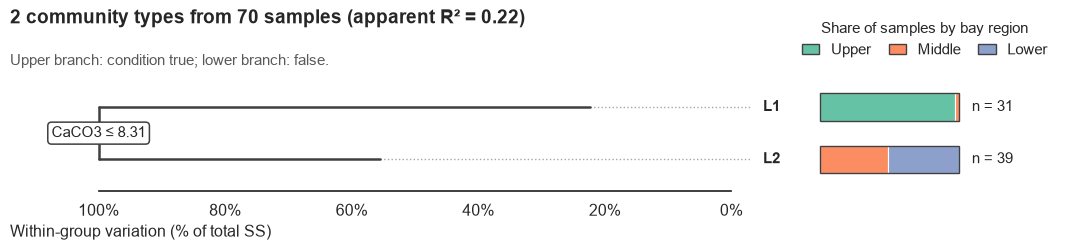

In [7]:
fig, ax, geom = plot_mrt_dendrogram(tree, feature_names, leaf_of_sample, sample_groups, group_order, group_colors)
plt.show()

## 5. Leaf summary table
One row per leaf, in the same top-to-bottom order as the figure: leaf label, number of samples, the share of total variation still left within that leaf, the full rule that defines it, and how many of its samples come from each group. This is the numerical backup for the figure.

In [8]:
def leaf_table(tree, geom, feature_names, leaf_of_sample, sample_groups, group_order):
    t = tree.tree_
    L, R = t.children_left, t.children_right
    names = [PRETTY_NAMES.get(f, f) for f in feature_names]
    rules = {}
    def walk(node, conds):                       # collect the conditions along the path to each leaf
        if L[node] == -1:
            rules[node] = " & ".join(conds) if conds else "(all samples)"
            return
        nm, thr = names[t.feature[node]], f"{t.threshold[node]:{THRESH_FMT}}"
        walk(L[node], conds + [f"{nm} \u2264 {thr}"])
        walk(R[node], conds + [f"{nm} > {thr}"])
    walk(0, [])
    comp = (pd.crosstab(pd.Series(np.asarray(leaf_of_sample), name="leaf"),
                        pd.Series(np.asarray(sample_groups), name="grp"))
              .reindex(columns=group_order, fill_value=0))
    rows = []
    for k, node in enumerate(geom["leaves"]):
        rows.append({"Leaf": f"L{k + 1}", "n": int(t.n_node_samples[node]),
                     "Within-leaf SS (% of total)": round(100 * geom["ss_frac"][node], 1),
                     "Rule": rules[node], **{grp.title(): int(comp.loc[node, grp]) for grp in group_order}})
    return pd.DataFrame(rows)

summary = leaf_table(tree, geom, feature_names, leaf_of_sample, sample_groups, group_order)
display(summary)
summary.to_csv(OUT_DIR / "leaf_summary.csv", index=False)

,Leaf,n,Within-leaf SS (% of total),Rule,Upper,Middle,Lower
0,L1,31,22.3,CaCO3 ≤ 8.31,30,1,0
1,L2,39,55.5,CaCO3 > 8.31,0,19,20


## 6. Save the figure
A PNG (slides, documents) and a PDF (vector, with editable text, for journals or further editing).

In [9]:
fig.savefig(OUT_DIR / "mrt_dendrogram.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT_DIR / "mrt_dendrogram.pdf", bbox_inches="tight")
print("Saved to", OUT_DIR.resolve())

Saved to /Users/Emily/Library/CloudStorage/Box-Box/Classes/OCS 7001 Scientific Computing (Fall 2026)/tree_figure_output


## 7. Optional: layout check on a deeper tree
A stress test for the figure design, not a result. It draws a larger pruned tree with the same function so you can see how the layout copes with more splits. The cross-validation in the analysis notebook did **not** support trees this large, so do not interpret the splits. Change `DEMO_LEAVES` to try other sizes, or skip this cell.

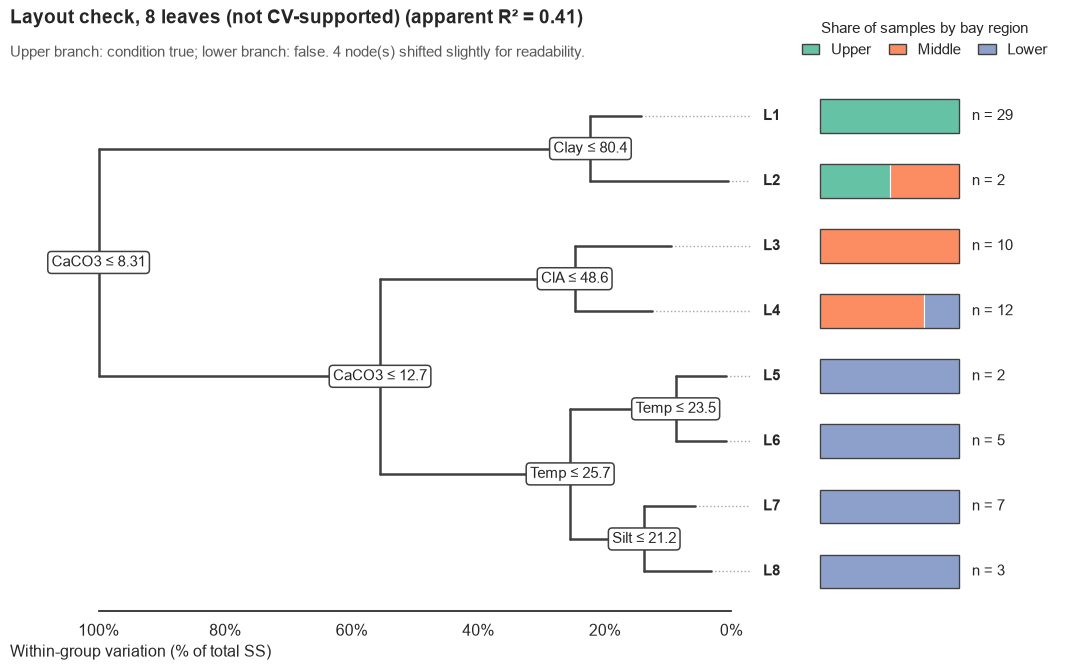

In [10]:
DEMO_LEAVES = 8
tree_demo = tree_with_leaves(DEMO_LEAVES)
demo_fig, demo_ax, demo_geom = plot_mrt_dendrogram(
    tree_demo, feature_names, tree_demo.apply(Xv), sample_groups, group_order, group_colors,
    title=f"Layout check, {tree_demo.get_n_leaves()} leaves (not CV-supported)")
plt.show()